In [1]:
# File system manangement
import os

os.getcwd()

'.'

In [2]:
# numpy and pandas for data manipulation
import numpy as np
import pandas as pd 

# sklearn preprocessing for dealing with categorical variables
from sklearn.preprocessing import LabelEncoder


# Suppress warnings 
import warnings
warnings.filterwarnings('ignore')

# matplotlib and seaborn for plotting
import matplotlib.pyplot as plt
import seaborn as sns

import timeit
import shap

In [3]:
from sklearn.metrics import confusion_matrix


# Read data

In [4]:
# Training data
app_train = pd.read_csv('data/application_train.csv')
print('Training data shape: ', app_train.shape)
app_train.head()

Training data shape:  (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
# testing data

app_test = pd.read_csv('data/application_test.csv')
print('Testing data shape: ', app_test.shape)
app_test.head()


Testing data shape:  (48744, 121)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
4,100038,Cash loans,M,Y,N,1,180000.0,625500.0,32067.0,625500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


# Exploratory data analysis

## Distribution of the TARGET column

In [6]:
app_train['TARGET'].value_counts()

0    282686
1     24825
Name: TARGET, dtype: int64

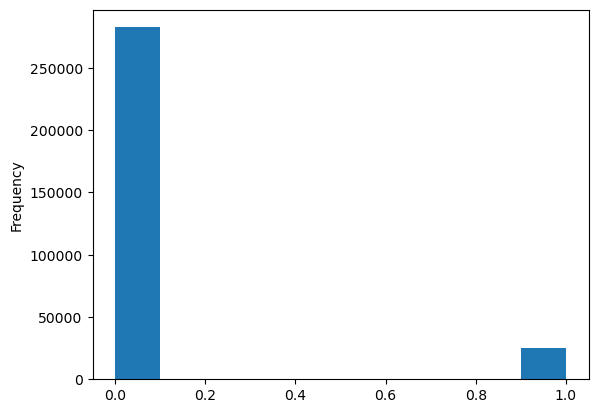

In [7]:
app_train['TARGET'].astype(int).plot.hist()
plt.show()

In [8]:
# the target variable is imbalanced. This can reduce the accuracy of a supervised classification model.


## Column types

In [9]:
# number of columns for each type
app_train.dtypes.value_counts()

float64    65
int64      41
object     16
dtype: int64

In [10]:
# number of distinct values taken by the categorical variables
app_train.select_dtypes('object').apply(pd.Series.nunique, axis = 0)

NAME_CONTRACT_TYPE             2
CODE_GENDER                    3
FLAG_OWN_CAR                   2
FLAG_OWN_REALTY                2
NAME_TYPE_SUITE                7
NAME_INCOME_TYPE               8
NAME_EDUCATION_TYPE            5
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
OCCUPATION_TYPE               18
WEEKDAY_APPR_PROCESS_START     7
ORGANIZATION_TYPE             58
FONDKAPREMONT_MODE             4
HOUSETYPE_MODE                 3
WALLSMATERIAL_MODE             7
EMERGENCYSTATE_MODE            2
dtype: int64

# Label / One hot encoder

## Variable encoding

In [11]:
# train

In [12]:
# Create a label encoder object
le = LabelEncoder()
le_count = 0

# Iterate through the columns
for col in app_train:
    if app_train[col].dtype == 'object':
        # If 2 or fewer unique categories
        if len(list(app_train[col].unique())) <= 2:
            # Train on the training data
            le.fit(app_train[col])
            # Transform both training and testing data
            app_train[col] = le.transform(app_train[col])
            
            # Keep track of how many columns were label encoded
            le_count += 1
            
print('%d columns were label encoded.' % le_count)

3 columns were label encoded.


In [13]:
# one-hot encoding of categorical variables
app_train = pd.get_dummies(app_train)

print('Training Features shape: ', app_train.shape)


Training Features shape:  (307511, 243)


In [14]:
# test

In [15]:
# Create a label encoder object
le = LabelEncoder()
le_count = 0

# Iterate through the columns
for col in app_test:
    if app_test[col].dtype == 'object':
        # If 2 or fewer unique categories
        if len(list(app_test[col].unique())) <= 2:
            # Train on the training data
            le.fit(app_test[col])
            # Transform both training and testing data
            app_test[col] = le.transform(app_test[col])
            
            # Keep track of how many columns were label encoded
            le_count += 1
            
print('%d columns were label encoded.' % le_count)

4 columns were label encoded.


In [16]:
# one-hot encoding of categorical variables
app_test = pd.get_dummies(app_test)

print('Testing Features shape: ', app_test.shape)


Testing Features shape:  (48744, 238)


## Check column consistency between the train and test datasets:

### What is the difference between the dataset columns?

In [17]:
colonnes_new_clients_a = list(app_test.columns)
colonnes_anciens_clients_a = list(app_train.columns)

difference_a = set(colonnes_new_clients_a).difference(set(colonnes_anciens_clients_a))
difference_b = set(colonnes_anciens_clients_a).difference(set(colonnes_new_clients_a))

In [18]:
difference_a

{'CODE_GENDER'}

In [19]:
difference_b

{'CODE_GENDER_F',
 'CODE_GENDER_M',
 'CODE_GENDER_XNA',
 'NAME_FAMILY_STATUS_Unknown',
 'NAME_INCOME_TYPE_Maternity leave',
 'TARGET'}

In [20]:
# the train dataset contains the target column. The algorithms will be trained on this dataset.
# there are also differences on the 'code_gender', 'name_family_status' and 'name_income_type' columns
# to use the test dataset in the dashboard at the end of the project, both datasets must be made consistent

### Column corrections:

#### correction colonne 'code gender'

In [21]:
app_test.rename(columns={'CODE_GENDER':'CODE_GENDER_M'},inplace=True)


In [22]:
colonnes_new_clients_a = list(app_test.columns)
colonnes_anciens_clients_a = list(app_train.columns)

difference_a = set(colonnes_new_clients_a).difference(set(colonnes_anciens_clients_a))
difference_b = set(colonnes_anciens_clients_a).difference(set(colonnes_new_clients_a))

In [23]:
difference_a

set()

In [24]:
difference_b

{'CODE_GENDER_F',
 'CODE_GENDER_XNA',
 'NAME_FAMILY_STATUS_Unknown',
 'NAME_INCOME_TYPE_Maternity leave',
 'TARGET'}

In [25]:
UN = [1]*(app_test.shape[0])

In [26]:
app_test['CODE_GENDER_F'] = UN - app_test['CODE_GENDER_M']

In [27]:
app_test['CODE_GENDER_XNA']= UN

#### correction colonne 'Name family status'

In [28]:
app_test['NAME_FAMILY_STATUS_Unknown']=UN

#### correction colonne 'Name income type'

In [29]:
app_test['NAME_INCOME_TYPE_Maternity leave']=UN

In [30]:
colonnes_new_clients_a = list(app_test.columns)
colonnes_anciens_clients_a = list(app_train.columns)

difference_a = set(colonnes_new_clients_a).difference(set(colonnes_anciens_clients_a))
difference_b = set(colonnes_anciens_clients_a).difference(set(colonnes_new_clients_a))

In [31]:
difference_a

set()

In [32]:
difference_b

{'TARGET'}

In [33]:
# the only remaining difference between the two datasets is the 'Target' column, which is expected.

# Anomalies in the values

## Client age:

In [34]:
# train

In [35]:
(app_train['DAYS_BIRTH'] / -365).describe()

count    307511.000000
mean         43.936973
std          11.956133
min          20.517808
25%          34.008219
50%          43.150685
75%          53.923288
max          69.120548
Name: DAYS_BIRTH, dtype: float64

In [36]:
# test :

(app_test['DAYS_BIRTH'] / -365).describe()

count    48744.000000
mean        44.022150
std         11.851782
min         20.104110
25%         34.235616
50%         43.246575
75%         53.800000
max         69.027397
Name: DAYS_BIRTH, dtype: float64

In [37]:
# Client age OK, nothing to report

## Client days employed:

In [38]:
app_train['DAYS_EMPLOYED'].describe()

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

In [39]:
app_test['DAYS_EMPLOYED'].describe()

count     48744.000000
mean      67485.366322
std      144348.507136
min      -17463.000000
25%       -2910.000000
50%       -1293.000000
75%        -296.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

In [40]:
## There is an issue with the maximum value (100 years employed!). Let's see what this value corresponds to,
## as it may tell us something about the database.

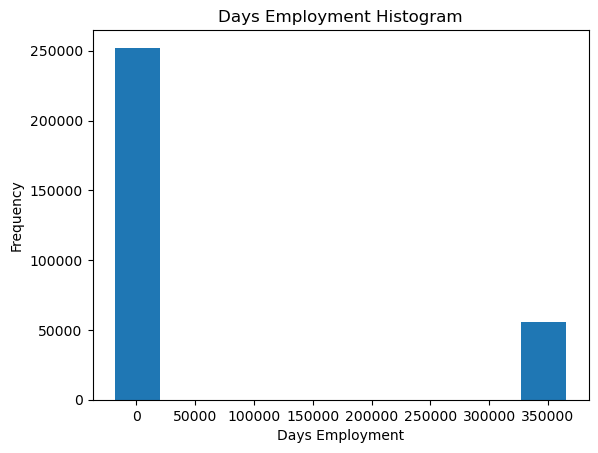

In [41]:
app_train['DAYS_EMPLOYED'].plot.hist(title = 'Days Employment Histogram')
plt.xlabel('Days Employment')
plt.show()

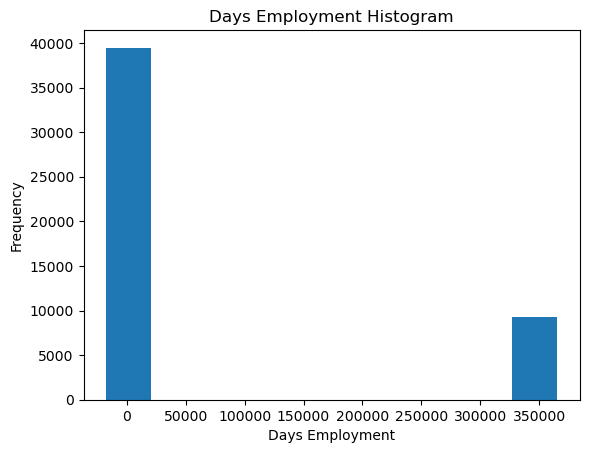

In [42]:
app_test['DAYS_EMPLOYED'].plot.hist(title = 'Days Employment Histogram')
plt.xlabel('Days Employment')
plt.show()

In [43]:
#train
anom = app_train[app_train['DAYS_EMPLOYED'] == 365243]
non_anom = app_train[app_train['DAYS_EMPLOYED'] != 365243]
print('The non-anomalies default on %0.2f%% of loans' % (100 * non_anom['TARGET'].mean()))
print('The anomalies default on %0.2f%% of loans' % (100 * anom['TARGET'].mean()))
print('There are %d anomalous days of employment' % len(anom))

The non-anomalies default on 8.66% of loans
The anomalies default on 5.40% of loans
There are 55374 anomalous days of employment


In [44]:
# individuals with 365243 days employed have, on average, fewer repayment difficulties
# than the others (5.40% vs 8.66% default rate)
# For information, we flag these individuals in a new 'days employed anom' column.

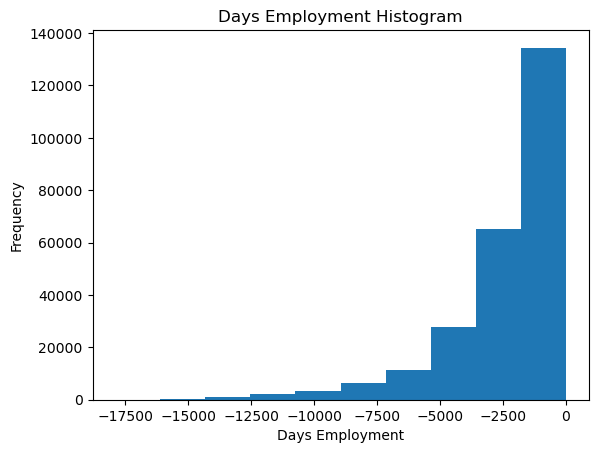

In [45]:
# Create the anomaly column
app_train['DAYS_EMPLOYED_ANOM'] = app_train["DAYS_EMPLOYED"] == 365243

# Replace the 365243 values with NaN
app_train['DAYS_EMPLOYED'].replace({365243: np.nan}, inplace = True)

app_train['DAYS_EMPLOYED'].plot.hist(title = 'Days Employment Histogram');
plt.xlabel('Days Employment');
plt.show()

In [46]:
# the distribution is now closer to what we expect

# Handling missing values

In [47]:
app_train = app_train.fillna(app_train.median())

In [48]:
app_test = app_test.fillna(app_test.median())

# -----------------

# Modelling:

## Train/test split

In [49]:
y = app_train['TARGET']

if 'TARGET' in app_train:
    train = app_train.drop(columns = ['TARGET'])
else:
    train = app_train.copy()
    
Xi = train.copy()

if 'SK_ID_CURR' in Xi:
    train_2 = Xi.drop(columns = ['SK_ID_CURR'])
else:
    train_2 = Xi.copy()
    
Xj = train_2.copy()
    



In [50]:
if 'SK_ID_CURR' in app_test:
    app_test_2 = app_test.drop(columns = ['SK_ID_CURR'])
else:
    app_test_2 = app_test.copy()
    
X_app_test = app_test_2.copy()

In [51]:
## we drop the column created earlier, since it will not be used in the supervised learning model

In [52]:
if 'DAYS_EMPLOYED_ANOM' in Xj:
    train_3 = Xj.drop(columns = ['DAYS_EMPLOYED_ANOM'])
else:
    train_3 = Xj.copy()
    
X = train_3.copy()

In [53]:
## check the differences between the test and train datasets

In [54]:
colonnes_new_clients_b = list(X_app_test.columns)
colonnes_anciens_clients_b = list(X.columns)

difference_a = set(colonnes_new_clients_b).difference(set(colonnes_anciens_clients_b))
difference_b = set(colonnes_anciens_clients_b).difference(set(colonnes_new_clients_b))

In [55]:
difference_a

set()

In [56]:
difference_b

set()

In [57]:
# split en train/test

In [58]:
from sklearn import model_selection
X_train, X_test, y_train, y_test = \
    model_selection.train_test_split(X, y, test_size=0.2)

In [59]:
# export the dataframe to retrieve the feature names later.

#X.head(1).to_csv('feature_names.csv')


In [60]:
# standardise the data
from sklearn import preprocessing

X_train_std = preprocessing.StandardScaler().fit_transform(X_train)
X_test_std = preprocessing.StandardScaler().fit_transform(X_test)

In [61]:
X_train_std.shape

(246008, 241)

# Baseline models without hyperparameter tuning

## Dummy

In [62]:
from sklearn.dummy import DummyClassifier


In [19]:
dummy_class = DummyClassifier()

start_time = timeit.default_timer()

dummy_class.fit(X_train, y_train)
elapsed = timeit.default_timer() - start_time

print(elapsed)

0.01602927700002965


In [20]:
y_pred = dummy_class.predict(X_test)


In [21]:
dummy_class.score(X, y)

0.9192711805431351

## Logistic Regression

In [63]:
from sklearn.linear_model import LogisticRegression


In [ ]:
# Make the model with the specified regularization parameter
log_reg = LogisticRegression(C = 0.01)

# Train on the training data
log_reg.fit(X_train_std, y_train)

LogisticRegression(C=0.01)

In [ ]:
y_pred_LR = log_reg.predict(X_test_std)

In [ ]:
log_reg.score(X,y)

0.5873968736077734

## Random Forest

In [64]:
from sklearn.ensemble import RandomForestClassifier


In [ ]:
# Make the random forest classifier
random_forest = RandomForestClassifier(n_estimators = 100, random_state = 50, verbose = 1, n_jobs = -1)

In [ ]:
# Train on the training data
random_forest.fit(X_train_std, y_train)

# Make predictions on the test data
y_pred_RF = random_forest.predict(X_test_std)

In [ ]:
random_forest.score(X,y)

0.9192711805431351

## XG Boost

In [65]:
import xgboost

In [ ]:
#XGB = xgboost.XGBRegressor(n_estimators=100,max_depth=10,eta=0.01,subsample=1,colsample_bytree=1)
XGB = xgboost.XGBClassifier()

In [ ]:
# Train on the training data
XGB.fit(X_train_std, y_train)

# Make predictions on the test data
y_pred_XGB = XGB.predict(X_test_std)

In [71]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred_XGB)

## Light GBM

In [66]:
import lightgbm

In [ ]:
LGBM = lightgbm.LGBMClassifier()


In [ ]:
# Train on the training data
LGBM.fit(X_train_std, y_train)

# Make predictions on the test data
y_pred_LGBM = LGBM.predict(X_test_std)

In [ ]:
LGBM.score(X,y)

0.9192711805431351

# Model optimisation on AUC

In [67]:
from sklearn.metrics import roc_auc_score


from sklearn.model_selection import GridSearchCV


## Linear Regression

In [ ]:
grid_LR = GridSearchCV(LogisticRegression(), param_grid={'C':[0.01,0.05,1,2]}, cv=5,
            scoring='roc_auc')

In [ ]:
start_time = timeit.default_timer()

grid_LR.fit(X_train_std, y_train)

elapsed = timeit.default_timer() - start_time

print(elapsed)

9.682986514999982


In [ ]:
grid_LR.best_params_

{'C': 0.01}

In [ ]:
model_LR = LogisticRegression(C=0.01)

> **Note (2026):** in the original version, the test-set AUC of the baseline models was computed on hard class predictions (`predict`), which caps the score around 0.50. The cells below were corrected to use `predict_proba` and need to be re-run. The cross-validated AUC (~0.74) and the business-metric optimisation further down are unaffected.

In [ ]:
# Train on the training data
model_LR.fit(X_train_std, y_train)

# Predicted probabilities on the test data (AUC must be computed on scores, not on hard labels)
predictions_modelLR = model_LR.predict_proba(X_test_std)[:, 1]

roc_auc_score(y_test,predictions_modelLR)

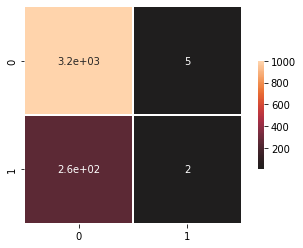

In [ ]:
cm_lr = confusion_matrix(y_test, predictions_modelLR)

import seaborn as sn

sn.heatmap(cm_lr, vmax=1000, center=0, annot=True,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

## Random Forest (too long to optimize)

In [ ]:
grid_RFC = GridSearchCV(RandomForestClassifier(), param_grid={'max_features':[0.0,1.0],
           'n_estimators':[100,500],
           'max_depth':[5.0,20.0],
           'min_samples_leaf':[1,5],
           'min_samples_split':[0.1,1.0],
           'n_jobs':[-1,1]}, cv=3,
            scoring='roc_auc')


In [ ]:
start_time = timeit.default_timer()

grid_RFC.fit(X_train_std, y_train)

elapsed = timeit.default_timer() - start_time

print(elapsed)

In [ ]:
grid_RFC.best_params_

In [ ]:
modelRFC = RandomForestClassifier(n_estimators = 100, random_state = 50, verbose = 1, n_jobs = -1)

In [ ]:
# Train on the training data
modelRFC.fit(X_train_std, y_train)

# Predicted probabilities on the test data (AUC must be computed on scores, not on hard labels)
predictions_modelRFC = modelRFC.predict_proba(X_test_std)[:, 1]

roc_auc_score(y_test,predictions_modelRFC)


## XG Boost

In [ ]:
grid_XGB = GridSearchCV(xgboost.XGBClassifier(eval_metric='logloss'), param_grid={'n_estimators':[100,500],
           'max_depth':[5,20],
           'eta':[0.01,1],
           'subsample':[0.1,2],
           'colsample_bytree':[0.1,2]}, cv=5,
            scoring='roc_auc')

In [ ]:
start_time = timeit.default_timer()

grid_XGB.fit(X_train_std, y_train)

elapsed = timeit.default_timer() - start_time

print(elapsed)



262.185685504


In [ ]:
grid_XGB.best_params_

{'colsample_bytree': 0.1,
 'eta': 0.01,
 'max_depth': 5,
 'n_estimators': 100,
 'subsample': 0.1}

In [ ]:
modelXGB = xgboost.XGBClassifier( colsample_bytree= 0.1, eta= 0.01, max_depth= 5, n_estimators= 100, subsample= 0.1,
                                 eval_metric='logloss')

In [ ]:
# Train on the training data
modelXGB.fit(X_train_std, y_train)

# Predicted probabilities on the test data (AUC must be computed on scores, not on hard labels)
predictions_modelXGB = modelXGB.predict_proba(X_test_std)[:, 1]

roc_auc_score(y_test,predictions_modelXGB)


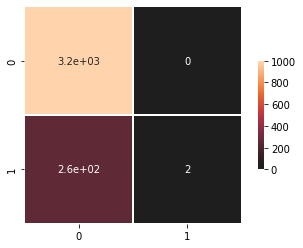

In [ ]:
cm_xgb = confusion_matrix(y_test, predictions_modelXGB)

import seaborn as sn

sn.heatmap(cm_xgb, vmax=1000, center=0, annot=True,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

## Light GBM

In [ ]:
grid_LGBM = GridSearchCV(lightgbm.LGBMClassifier(), param_grid={'num_leaves': [30, 150],
    'reg_alpha': [0.1, 0.5],
    'min_data_in_leaf': [100, 200],
    'lambda_l1': [0, 1],
    'lambda_l2': [0, 1]}, cv=5,
            scoring='roc_auc')

In [ ]:
start_time = timeit.default_timer()

grid_LGBM.fit(X_train_std, y_train)

elapsed = timeit.default_timer() - start_time

print(elapsed)

358.45478548100004


In [ ]:
grid_LGBM.best_params_

{'lambda_l1': 1,
 'lambda_l2': 1,
 'min_data_in_leaf': 200,
 'num_leaves': 30,
 'reg_alpha': 0.1}

In [ ]:
model_LGBM = lightgbm.LGBMClassifier(lambda_l1= 0, lambda_l2 = 1, min_data_in_leaf = 200, num_leaves = 30, reg_alpha = 0.1)

In [ ]:
# Train on the training data
model_LGBM.fit(X_train_std, y_train)

# Predicted probabilities on the test data (AUC must be computed on scores, not on hard labels)
predictions_modelLGBM = model_LGBM.predict_proba(X_test_std)[:, 1]

roc_auc_score(y_test,predictions_modelLGBM)


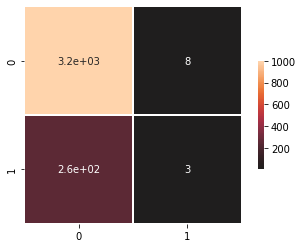

In [ ]:
cm_lgbm = confusion_matrix(y_test, predictions_modelLGBM)

import seaborn as sn

sn.heatmap(cm_lgbm, vmax=1000, center=0, annot=True,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

In [ ]:
## not very conclusive. There are almost no 1s to predict.
## let's run the test again after rebalancing the classes and look at the impact on the AUC score.

# Model optimization with ADASYN / SMOTE / Undersampling from IMBLEARN:

In [71]:
from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.datasets import make_classification
from imblearn.pipeline import Pipeline

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score
from numpy import mean
from imblearn.over_sampling import ADASYN
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

under = RandomUnderSampler(sampling_strategy=0.1)


can use SMOTE(sampling_strategy=0.1), where 0.1 corresponds to the desired ratio of the number of samples in the minority class over the number of samples in the majority class after resampling. Therefore, the ratio is expressed as \alpha_{os} = N_{rm} / N_{M} where N_{rm} is the number of samples in the minority class after resampling and N_{M} is the number of samples in the majority class.

In [ ]:
# as seen at the start, the TARGET column is imbalanced.
# If the model is trained as is, it will learn almost only from TARGET = 0.
# This gives an accuracy close to 1, but wrong predictions for a new sample of clients.
# To address this, we can oversample or undersample the population.
# Several techniques exist in the imblearn library.
# They can be combined with GridSearch, provided a pipeline is created first.
# The pipeline rebalances the distribution on every fold created by GridSearch.
# Here, the goal is to keep an acceptable model run time.
# Whenever possible, we use ADASYN or SMOTE.
# If the model is too slow, we use RandomUnderSampler.

### Logistic regression

In [70]:
LR = LogisticRegression()
adasyn = ADASYN()
grid_LR={'class__C':[0.01,0.05,1,2]}


# define pipeline
pipeline_LR = Pipeline([('sampling', under), ('class', LR)])

# evaluate pipeline

grid_cv_LR = GridSearchCV(pipeline_LR, grid_LR, scoring = 'roc_auc', cv = 5)
   
grid_cv_LR.fit(X_train_std, y_train)

grid_cv_LR.best_score_


0.7448704886415076

In [ ]:
grid_cv_LR.best_params_

{'class__C': 0.05}

In [ ]:
LR_opt = LogisticRegression(C=0.01)

In [ ]:
# Train on the training data
LR_opt.fit(X_train_std, y_train)

pred_LR_opt = LR_opt.predict_proba(X_test_std)[:, 1]

roc_auc_score(y_test, pred_LR_opt)

### XGB

In [ ]:
XGB = xgboost.XGBClassifier()
adasyn = ADASYN()
grid_XGB={'class__n_estimators':[100,500],
           'class__max_depth':[5,20],
           'class__eta':[0.01,1],
           'class__subsample':[0.1,2],
           'class__colsample_bytree':[0.1,2]}

# define pipeline
pipeline_XGB = Pipeline([('sampling', under), ('class', XGB)])

# evaluate pipeline

grid_cv_XGB = GridSearchCV(pipeline_XGB, grid_XGB, scoring = 'roc_auc', cv = 3)
   
grid_cv_XGB.fit(X_train_std, y_train)

grid_cv_XGB.best_score_

[09:16:53] WARNING: C:/Users/Administrator/workspace/xgboost-win64_release_1.4.0/src/learner.cc:1095: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'binary:logistic' was changed from 'error' to 'logloss'. Explicitly set eval_metric if you'd like to restore the old behavior.
[09:17:00] WARNING: C:/Users/Administrator/workspace/xgboost-win64_release_1.4.0/src/learner.cc:1095: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'binary:logistic' was changed from 'error' to 'logloss'. Explicitly set eval_metric if you'd like to restore the old behavior.
[09:17:08] WARNING: C:/Users/Administrator/workspace/xgboost-win64_release_1.4.0/src/learner.cc:1095: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'binary:logistic' was changed from 'error' to 'logloss'. Explicitly set eval_metric if you'd like to restore the old behavior.
[09:17:19] WARNING: C:/Users/Administrator/workspace/xgboost-win64_rel

In [ ]:
grid_cv_XGB.best_params_

### Light GBM

In [76]:
LGBM = lightgbm.LGBMClassifier()
adasyn = ADASYN()
grid_LGBM = {'class__num_leaves': [30, 150],
    'class__reg_alpha': [0.1, 0.5],
    'class__min_data_in_leaf': [100, 200],
    'class__lambda_l1': [0, 1],
    'class__lambda_l2': [0, 1]}

# define pipeline
pipeline_LGBM = Pipeline([('sampling', adasyn), ('class', LGBM)])

# evaluate pipeline

grid_cv_LGBM = GridSearchCV(pipeline_LGBM, grid_LGBM, scoring = 'roc_auc', cv = 5)
   
grid_cv_LGBM.fit(X_train_std, y_train)

grid_cv_LGBM.best_score_

In [ ]:
grid_cv_LGBM.best_params_

see: https://towardsdatascience.com/imbalanced-class-sizes-and-classification-models-a-cautionary-tale-part-2-cf371500d1b3
The gap between the mean cross-validated AUC and the test AUC is too large.
Anomaly?

# Building our business metric

### We want to give more weight to false positives:

In [71]:
from sklearn.metrics import fbeta_score, make_scorer

# for the fbeta_score, we choose a high beta. In short, the higher the f-score, the fewer false positives.

f_scorer = make_scorer(fbeta_score, beta=10)

f_scorer

make_scorer(fbeta_score, beta=10)

### Logistic regression

In [ ]:
LR = LogisticRegression()
adasyn = ADASYN()
grid_LR={'class__C':[0.01,0.05,1,2]}

under = RandomUnderSampler(sampling_strategy=0.5)


# define pipeline
pipeline_LR = Pipeline([('sampling', adasyn), ('class', LR)])

# evaluate pipeline

grid_cv_LR = GridSearchCV(pipeline_LR, grid_LR, scoring = f_scorer, cv = 5)
   
grid_cv_LR.fit(X_train_std, y_train)

grid_cv_LR.best_score_

In [ ]:
grid_cv_LR.best_params_

{'class__C': 0.05}

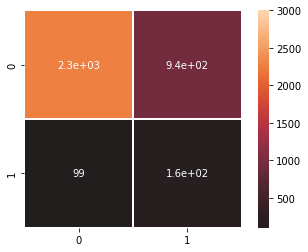

In [ ]:
cm_lr = confusion_matrix(y_test, grid_cv_LR.predict(X_test_std))

import seaborn as sn

sn.heatmap(cm_lr, vmax=3000, center=0, annot=True,
            square=True, linewidths=.5, cbar_kws={"shrink": 1})

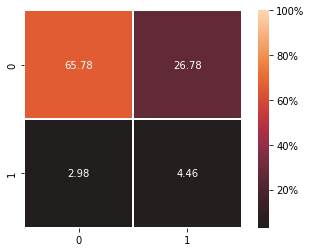

In [ ]:
cm_lr = confusion_matrix(y_test, grid_cv_LR.predict(X_test_std))
cm_lr_prcnt = cm_lr/np.sum(cm_lr)*100

sn.heatmap(cm_lr_prcnt, vmax=100, center=0, annot=True, fmt='.2f',
            square=True, linewidths=.5, cbar_kws={"shrink": 1,'format': '%.0f%%'})


### XG Boost

In [ ]:
XGB = xgboost.XGBClassifier()
adasyn = ADASYN()
smote = SMOTE()

grid_XGB={'class__n_estimators':[600,700],
           'class__max_depth':[40,50],
           'class__eta':[1,2],
           'class__subsample':[0.01,0.05],
           'class__colsample_bytree':[0.1]}

# define pipeline
pipeline_XGB = Pipeline([('sampling', smote), ('class', XGB)])

# evaluate pipeline

grid_cv_XGB = GridSearchCV(pipeline_XGB, grid_XGB, scoring = f_scorer, cv = 3)
   
grid_cv_XGB.fit(X_train_std, y_train)

grid_cv_XGB.best_score_

In [ ]:
grid_cv_XGB.best_params_

In [ ]:
cm_xgb = confusion_matrix(grid_cv_XGB.predict(X_test_std),y_test)

import seaborn as sn

sn.heatmap(cm_xgb, vmax=250, center=0, annot=True,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

In [ ]:
y_test.value_counts

<bound method IndexOpsMixin.value_counts of 8527     0
3016     0
11611    0
4320     0
8578     0
        ..
8942     0
12774    0
13634    0
11320    1
222      0
Name: TARGET, Length: 3495, dtype: int64>

### LightGBM (far too slow with SMOTE, we use undersampling)

In [147]:
under = RandomUnderSampler(sampling_strategy=0.5)

X_res_test, y_res_test = under.fit_resample(X, y)

X.shape


(307511, 241)

In [148]:
y_res_test.value_counts()

0    49650
1    24825
Name: TARGET, dtype: int64

In [149]:
LGBM = lightgbm.LGBMClassifier()
adasyn = ADASYN()
smote = SMOTE()

under = RandomUnderSampler(sampling_strategy=0.5)


grid_LGBM = {'class__num_leaves': [200,300],
    'class__reg_alpha': [0, 0.5],
    'class__min_data_in_leaf': [800,1000],
    'class__lambda_l1': [0, 1],
    'class__lambda_l2': [1, 2]}

# define pipeline
pipeline_LGBM = Pipeline([('sampling', under), ('class', LGBM)])

# evaluate pipeline

grid_cv_LGBM = GridSearchCV(pipeline_LGBM, grid_LGBM, scoring = f_scorer, cv = 3)
   
grid_cv_LGBM.fit(X_train_std, y_train)

grid_cv_LGBM.best_score_

[LightGBM] [Warning] min_data_in_leaf is set=800, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=800
[LightGBM] [Warning] lambda_l1 is set=0, reg_alpha=0 will be ignored. Current value: lambda_l1=0
[LightGBM] [Warning] lambda_l2 is set=1, reg_lambda=0.0 will be ignored. Current value: lambda_l2=1
[LightGBM] [Warning] min_data_in_leaf is set=800, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=800
[LightGBM] [Warning] lambda_l1 is set=0, reg_alpha=0 will be ignored. Current value: lambda_l1=0
[LightGBM] [Warning] lambda_l2 is set=1, reg_lambda=0.0 will be ignored. Current value: lambda_l2=1
[LightGBM] [Warning] min_data_in_leaf is set=800, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=800
[LightGBM] [Warning] lambda_l1 is set=0, reg_alpha=0 will be ignored. Current value: lambda_l1=0
[LightGBM] [Warning] lambda_l2 is set=1, reg_lambda=0.0 will be ignored. Current value: lambda_l2=1
[LightGBM] [Warning] min_data_in_leaf

0.4295288176638628

In [150]:
grid_cv_LGBM.best_params_

{'class__lambda_l1': 0,
 'class__lambda_l2': 1,
 'class__min_data_in_leaf': 800,
 'class__num_leaves': 200,
 'class__reg_alpha': 0.5}

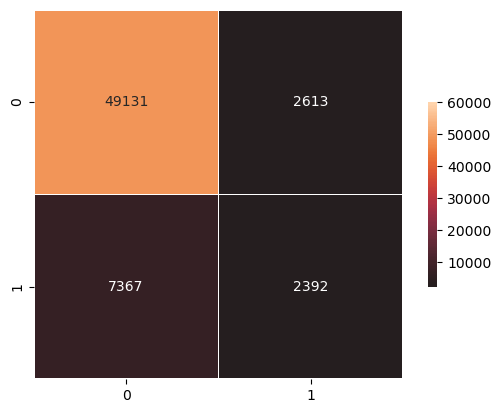

In [78]:
cm_lgbm = confusion_matrix(grid_cv_LGBM.predict(X_test_std),y_test)

import seaborn as sn

sn.heatmap(cm_lgbm, vmax=60000, center=0, annot=True,
            square=True, linewidths=.5, cbar_kws={"shrink": .5},fmt='g')

plt.show()

In [84]:
model_LGBM_pickle.predict(X_test_std)[0]

0

In [ ]:
# the LightGBM confusion matrix results are satisfactory. We keep this model for the next steps.

### Serialise a model:

In [72]:
from joblib import dump, load
#dump(grid_cv_LGBM, 'grid_cv_LGBM.joblib') 
import pickle

In [153]:
grid_cv_LGBM = load('grid_cv_LGBM.joblib') 

In [154]:
grid_cv_LGBM.best_params_

{'class__lambda_l1': 0,
 'class__lambda_l2': 1,
 'class__min_data_in_leaf': 800,
 'class__num_leaves': 200,
 'class__reg_alpha': 0.5}

In [155]:
# Saving model to disk
pickle.dump(grid_cv_LGBM, open('model_LGBM_pickle.pkl','wb'))


In [75]:
# Loading model to compare the results
model_LGBM_pickle = pickle.load(open('model_LGBM_pickle.pkl','rb'))

# Best features choice

## features_importances_

In [75]:
features = list(X.columns)

In [ ]:
# XG Boost

feature_importance_values_modelXGB = grid_cv_XGB.best_estimator_.named_steps["class"].feature_importances_

feature_importances_modelXGB = pd.DataFrame({'feature': features, 'importance': feature_importance_values_modelXGB})

In [51]:
# LGBM


feature_importance_values_modelLGBM = grid_cv_LGBM.best_estimator_.named_steps["class"].feature_importances_

feature_importances_modelLGBM = pd.DataFrame({'feature': features, 'importance': feature_importance_values_modelLGBM})

In [52]:
def plot_feature_importances(df):
    """
    Plot importances returned by a model. This can work with any measure of
    feature importance provided that higher importance is better. 
    
    Args:
        df (dataframe): feature importances. Must have the features in a column
        called `features` and the importances in a column called `importance
        
    Returns:
        shows a plot of the 15 most importance features
        
        df (dataframe): feature importances sorted by importance (highest to lowest) 
        with a column for normalized importance
        """
    
    # Sort features according to importance
    df = df.sort_values('importance', ascending = False).reset_index()
    
    # Normalize the feature importances to add up to one
    df['importance_normalized'] = df['importance'] / df['importance'].sum()

    # Make a horizontal bar chart of feature importances
    plt.figure(figsize = (10, 6))
    ax = plt.subplot()
    
    # Need to reverse the index to plot most important on top
    ax.barh(list(reversed(list(df.index[:15]))), 
            df['importance_normalized'].head(15), 
            align = 'center', edgecolor = 'k')
    
    # Set the yticks and labels
    ax.set_yticks(list(reversed(list(df.index[:15]))))
    ax.set_yticklabels(df['feature'].head(15))
    
    # Plot labeling
    plt.xlabel('Normalized Importance'); plt.title('Feature Importances')
    plt.show()
    
    return df

In [53]:
#feature_importances_domain_sorted = plot_feature_importances(feature_importances_modelXGB)


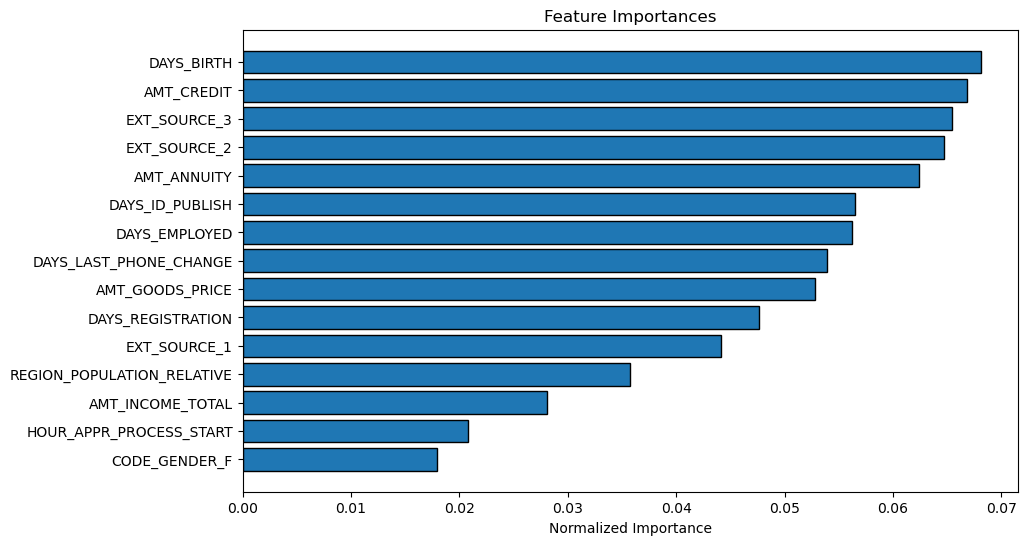

In [54]:
feature_importances_domain_sorted = plot_feature_importances(feature_importances_modelLGBM)


## Differences between application train and application test

In [76]:
colonnes_new_clients = list(X_app_test.columns)
colonnes_anciens_clients = features

In [77]:
difference_1 = set(colonnes_new_clients).difference(set(colonnes_anciens_clients))
difference_2 = set(colonnes_anciens_clients).difference(set(colonnes_new_clients))

In [78]:
difference_1

set()

In [79]:
difference_2

set()

## Shap

In [49]:
# Train :

sm = SMOTE()
under = RandomUnderSampler(sampling_strategy=0.5)

# Standardised (centred and scaled) data:
X_std = preprocessing.StandardScaler().fit_transform(X)

# Undersampling :
X_res, y_res = under.fit_resample(X_std, y)


# Add the column names to the dataframe:

pd_X = pd.DataFrame(X_std, columns = features)
pd_X_test = pd.DataFrame( X_test_std, columns = features)
pd_X_train = pd.DataFrame( X_train_std, columns = features)


# Add the 'SK_ID_CURR' column (initially removed from X_std for modelling)
pd_X['SK_ID_CURR'] = Xi['SK_ID_CURR']

In [ ]:
# Test :

# Standardised (centred and scaled) data:
X_app_test_std = preprocessing.StandardScaler().fit_transform(X_app_test)

# Add the column names to the dataframe:
pd_X_app_test = pd.DataFrame(X_app_test_std, columns = features)

# Add the 'SK_ID_CURR' column
pd_X_app_test['SK_ID_CURR'] = app_test['SK_ID_CURR']

In [ ]:
#grid_cv_LGBM.best_estimator_.named_steps["class"]

#### LGBM

In [44]:
# init :
shap.initjs()

<IPython.core.display.HTML object>

In [176]:
# Build the LGBM model with the best_params

LGBM_best = lightgbm.LGBMClassifier(lambda_l1= 0, lambda_l2= 1, min_data_in_leaf= 800,
 num_leaves= 200, reg_alpha= 0.5)


# fit on the undersampled dataset:
LGBM_best.fit(X_res, y_res)

# serialise the model
from joblib import dump, load
dump(LGBM_best, 'LGBM_best.joblib') 

# Saving model to disk
pickle.dump(LGBM_best, open('LGBM_best.pkl','wb'))

In [178]:
Id_Client = 100010
data_for_prediction = pd_X[pd_X['SK_ID_CURR']==Id_Client][features] # use 1 row of data here. Could use multiple rows if desired

# Create object that can calculate shap values
explainer = shap.TreeExplainer(LGBM_best)

# Calculate Shap values
shap_values = explainer.shap_values(data_for_prediction)

#shap.initjs()
shap.force_plot(explainer.expected_value[1], shap_values[1], data_for_prediction)

## Sample the dataframes to keep the Streamlit dashboard responsive:

In [ ]:
# take a sample from the dataframe :
pd_X.shape

# Create app test and app train samples:
pd_X_sample = pd_X.sample(n=5000)
pd_X_app_test_sample = pd_X_app_test.sample(n=1000)


In [110]:
# keep the same individuals in the standardised dataframes and the original dataframes:
# retrieve the list of individuals in liste_totale and liste_test:

liste_totale = list(pd_X_sample['SK_ID_CURR'])
liste_test = list(pd_X_app_test_sample['SK_ID_CURR'])

# keep only these individuals in the original dataframes:
app_train_sample = app_train.query('SK_ID_CURR== @liste_totale')
app_test_sample = app_test.query('SK_ID_CURR== @liste_test')

In [118]:
# sort the dataframes by client ID:

app_test_sample.sort_values(by=['SK_ID_CURR'],inplace = True)
app_train_sample.sort_values(by=['SK_ID_CURR'],inplace = True)

pd_X_app_test_sample.sort_values(by=['SK_ID_CURR'],inplace = True)
pd_X_sample.sort_values(by=['SK_ID_CURR'],inplace = True)

# Create a JSON file:

In [20]:
# app_train.to_json("app_train.json")

# Annexes

In [ ]:
client_dict = pd_X_app_test[pd_X_app_test['SK_ID_CURR']==100001][features].to_dict('records')

client_dict[0]

#pd_X[pd_X['SK_ID_CURR']==100010][features].to_json("justpourfun.json")

pd_X[pd_X['SK_ID_CURR']==100010][features].to_dict('records')

pd_X[pd_X['SK_ID_CURR']==100010][features]

In [ ]:
app_train[app_train['SK_ID_CURR']==100002]['TARGET']